<a href="https://colab.research.google.com/github/Neethu-Teacher/Assignment-1/blob/main/Assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question No:1- Load the dataset and handle missing data**

In [ ]:
import pandas as pd
import numpy as np
# Load the wine Quality dataset
url = "/content/winequality-red.csv"
df = pd.read_csv(url, sep=';')
# Display the first five rows
print(df.head())
# Check for missing values.
print("Missing values before handling:")
print(df.isnull().sum())
# Replace missing values with the mean of each column
df.fillna(df.mean(numeric_only=True), inplace=True)
# Check missing values after handling.
print("Missing values after handling:")
print(df.isnull().sum())
print("Dataset shape:", df.shape)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

**Question no:2 Extract alcohol and citric acid as vectors**

In [4]:
import pandas as pd

# Define url and extract alcohol and citric acid as Numpy vectors
url = "/content/winequality-red.csv"
df = pd.read_csv(url, sep=';')
alcohol_vector = df['alcohol'].to_numpy()
citric_acid_vector = df['citric acid'].to_numpy()
# Display the first 10 elements
print("Alcohol vector:")
print(alcohol_vector[:10])
print("\ncitric acid vector:")
print(citric_acid_vector[:10])
# Display vector dimensions
print("\nAlcohol vector shape:", alcohol_vector.shape)
print("citric acid vector shape:", citric_acid_vector.shape)

Alcohol vector:
[ 9.4  9.8  9.8  9.8  9.4  9.4  9.4 10.   9.5 10.5]

citric acid vector:
[0.   0.   0.04 0.56 0.   0.   0.06 0.   0.02 0.36]

Alcohol vector shape: (1599,)
citric acid vector shape: (1599,)


**Question NO:3 Calculate the covariance matrix**

In [5]:
# select two features
import pandas as pd
import numpy as np
url = "/content/winequality-red.csv"
df = pd.read_csv(url, sep=';')
x= df[['alcohol','density']].to_numpy()
# calculate the covariance matrix
covariance_matrix=np.cov(x.T)
# Display the covariance matrix
print("covariance matrix:")
print(covariance_matrix)


covariance matrix:
[[ 1.13564740e+00 -9.97951790e-04]
 [-9.97951790e-04  3.56202945e-06]]


**Question No:4 Perform eigen decomposition**


In [6]:
# perform eigen decomposition
eigenvalues, eigenvectors = np.linalg.eig(covariance_matrix)

# Sort eigenvalues in descending order
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

# Display eigenvalues
print("Eigenvalues:")
print(eigenvalues)

# Display corresponding eigenvectors
print("\nEigenvectors:")
print(eigenvectors)

# Display each eigenvalue with its corresponding eigenvector
print("\nTop eigenvalue:", eigenvalues[0])
print("Corresponding eigenvector:", eigenvectors[:, 0])

print("\nSecond eigenvalue:", eigenvalues[1])
print("Corresponding eigenvector:", eigenvectors[:, 1])

Eigenvalues:
[1.13564827e+00 2.68507580e-06]

Eigenvectors:
[[ 9.99999614e-01  8.78753184e-04]
 [-8.78753184e-04  9.99999614e-01]]

Top eigenvalue: 1.135648271954124
Corresponding eigenvector: [ 9.99999614e-01 -8.78753184e-04]

Second eigenvalue: 2.685075802669908e-06
Corresponding eigenvector: [8.78753184e-04 9.99999614e-01]


**Question No:5 Find the most common wine quality**

In [7]:
# Count the occurrence of each wine quality score
import pandas as pd
url = "/content/winequality-red.csv"
df = pd.read_csv(url, sep=';')
quality_counts = df['quality'].value_counts().sort_index()

print("Wine Quality Distribution:")
print(quality_counts)

# Find the most common quality score
most_common_quality = df['quality'].mode()[0]

print("\nMost common wine quality score:",
      most_common_quality)

print("Number of wines with this quality:",
      quality_counts[most_common_quality])

# Calculate percentage distribution
quality_percentage = df['quality'].value_counts(
    normalize=True
).sort_index() * 100

print("\nQuality Percentage Distribution:")
print(quality_percentage.round(2))


Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Most common wine quality score: 5
Number of wines with this quality: 681

Quality Percentage Distribution:
quality
3     0.63
4     3.31
5    42.59
6    39.90
7    12.45
8     1.13
Name: proportion, dtype: float64


**Visualize the quality distribution**

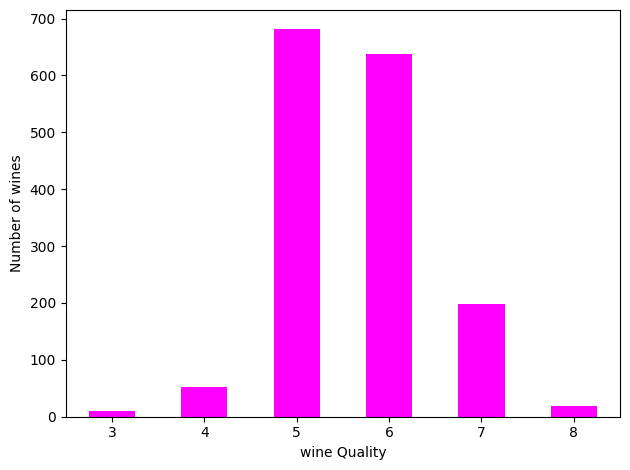

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
quality_counts.plot(kind='bar',color= 'Magenta')
plt.xlabel('wine Quality')
plt.ylabel('Number of wines')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Interpretation:
 In the standard red wine dataset specified in the       assignment, ** quality 5 is the most common score.**


---


 Quality scores 5 and 6 account for a large proportion of the wines.


---
 Very low and very high quality scores occur less frequently.


---
The distribution is concentrated around the middle quality scores rather than being evenly distributed.